## Match Baseline Setup
Same data, split and folds as `lr_baseline.ipynb`: the feature-engineered file (`data/processed/model/model_features.csv`),
training on `split == "train"` with the shared `cv_fold` column, and one final check on the held-out `split == "test"`.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import PredefinedSplit, GroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             average_precision_score, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
import joblib

DATA_DIR = Path("../../../data/processed/model")      # output of notebooks/modeling/Feature_Engineering.ipynb
OUTPUT_DIR = "../../../models/lr_tfidf_tuned"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # same decision as the baseline

# Threshold rule (Step 8). "max_f1" = best balance of precision and recall.
# "precision_floor" = highest recall while keeping precision >= PRECISION_FLOOR (stricter about false positives).
THRESHOLD_RULE = "max_f1"
PRECISION_FLOOR = 0.96

dictionary = pd.read_csv(DATA_DIR / "feature_dictionary.csv")
CATEGORICAL = dictionary.loc[dictionary["type"] == "categorical", "feature"].tolist()
df = pd.read_csv(DATA_DIR / "model_features.csv", low_memory=False, dtype={c: str for c in CATEGORICAL})
print("Shape:", df.shape)

Shape: (26678, 151)


In [2]:
FEATURES_ALL = dictionary["feature"].tolist()     # agreed drops, leakage removal and engineering done upstream
print("Features in the dictionary:", len(FEATURES_ALL), "| categorical:", len(CATEGORICAL))

Features in the dictionary: 121 | categorical: 12


In [3]:
TARGET = "vae_positive_local"
labeled = df[df["split"] == "train"].copy()      # training rows ("labeled" keeps the name used below)
test = df[df["split"] == "test"].copy()
y = labeled[TARGET].astype(int)
y_test = test[TARGET].astype(int)
groups = labeled["unitid"]
print("Training programs:", len(labeled), "| schools:", groups.nunique(), f"| pass rate: {y.mean():.1%}")
print("Held-out test programs:", len(test), "| schools:", test["unitid"].nunique(), f"| pass rate: {y_test.mean():.1%}")

Training programs: 5619 | schools: 1642 | pass rate: 78.3%
Held-out test programs: 1405 | schools: 437 | pass rate: 78.4%


In [4]:
def build_text(frame):
    text = (frame["cipdesc"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]
test["program_text"] = df.loc[test.index, "program_text"]
print("Unique text values:", df["program_text"].nunique())

Unique text values: 360


## Numeric features (with the tuning changes)

Same features as the baseline (the feature dictionary: leakage, IDs, fairness-only and duplicate formats were removed
in feature engineering, and categoricals are one-hot encoded), then:

**Change 1: remove overlapping features.** Each pair below carries nearly the same information (|r| ≥ 0.9 on the
training rows). Keeping both makes logistic regression split the effect between them, often with opposite signs.

| Removed | Kept instead | Overlap |
|---|---|---|
| `tuitionfee_in` | `costt4_a`, `tuition_to_wage` | Tuition is part of the cost of attendance (r = 0.93) and of tuition-to-wage (r = 0.92) |
| `cost_to_wage` | `program_cost` | Program cost divided by a field-level wage (r = 0.90) |
| `ipedscount2` | `ipedscount1` | Completions in consecutive years (r = 0.94) |
| `offers_grad` | `offers_cert_12to52wks` | Nearly the same schools (r = 0.99) |
| `hours_per_month` | `length_in_credit_hours` | Driven by the length unit (r = 0.95) |
| `etpl_natl_n_with_outcomes` | `etpl_natl_n_programs` | Count of ETPL programs vs. those with outcomes (r = 0.97) |
| `xw_skill_record_count` | `xw_unique_software_skills` | Both count O*NET technology records (r = 0.91) |
| `py_offcampus_family_other` | `py_offcampus_other` | Near-copy |
| `tuitionfee_in_was_missing`, `costt4_a_was_missing`, `ay_books_supplies_missing` | `has_program_cost` | Flag the same schools with no IPEDS price data (r ≥ 0.97) |
| `avgfacsal_was_missing`, `pftfac_was_missing` | `degree_granting` | Same schools (r ≥ 0.90) |
| `ret_ftl4_was_missing`, `prog_supplies_missing` | `c150_l4_was_missing`, `py_books_supplies_missing` | Same missingness pattern (r ≈ 0.94) |

**Change 2: `log1p` on skewed counts and dollars** (skew > 1, non-negative, not 0/1 flags), so a few very large
schools or prices don't dominate.

In [5]:
CAT_FEATURES = [c for c in CATEGORICAL if c != "cipcode"]          # TF-IDF text already identifies the field
BASELINE_FEATURES = [c for c in FEATURES_ALL if c not in CATEGORICAL]   # numeric, as in the baseline
DEMOGRAPHICS = ["ugds_white", "ugds_black", "ugds_hisp", "ugds_asian", "ugds_aian", "ugds_nhpi", "ugds_2mor"]
if INCLUDE_DEMOGRAPHICS:
    BASELINE_FEATURES += DEMOGRAPHICS

REDUNDANT = ["tuitionfee_in", "cost_to_wage", "ipedscount2", "offers_grad", "hours_per_month",
             "etpl_natl_n_with_outcomes", "xw_skill_record_count", "py_offcampus_family_other",
             # missing-value flags that mark the same schools (|r| >= 0.9)
             "tuitionfee_in_was_missing", "costt4_a_was_missing", "ay_books_supplies_missing",
             "avgfacsal_was_missing", "pftfac_was_missing", "ret_ftl4_was_missing", "prog_supplies_missing"]
REDUNDANT = [c for c in REDUNDANT if c in BASELINE_FEATURES]
FEATURES = [c for c in BASELINE_FEATURES if c not in REDUNDANT]

lab_num = labeled[FEATURES]
is_binary = lab_num.apply(lambda s: s.dropna().isin([0, 1]).all())
LOG_FEATURES = [c for c in FEATURES if not is_binary[c] and lab_num[c].min() >= 0 and abs(lab_num[c].skew()) > 1]
PLAIN_FEATURES = [c for c in FEATURES if c not in LOG_FEATURES]

print("Baseline numeric features:", len(BASELINE_FEATURES))
print(f"Removed as overlapping: {len(REDUNDANT)}")
print(f"Tuned: {len(FEATURES)} numeric ({len(LOG_FEATURES)} log-transformed) + {len(CAT_FEATURES)} categorical one-hot")

Baseline numeric features: 109
Removed as overlapping: 15
Tuned: 94 numeric (35 log-transformed) + 11 categorical one-hot


## Tuned pipeline

| Piece | Setting |
|---|---|
| `TfidfVectorizer` | words + 2-word phrases, English stop words, `sublinear_tf`; `max_features` and `min_df` tuned in Step 7 |
| Log block | `log1p` → median fill → scale |
| Plain numeric block | median fill → scale |
| `OneHotEncoder` | the low-cardinality categoricals (`control`, `iclevel`, `locale`, `bea_region`, `cip_series`, ...); categories with < 10 programs grouped together |
| `LogisticRegression` | L2, `C` tuned, **no class weighting** (see Step 9) |

`make_baseline_pipeline` rebuilds the `lr_baseline.ipynb` model exactly (C = 0.1, balanced weights), for side-by-side comparisons.

In [6]:
def make_tuned_pipeline(C=0.3, max_features=500, min_df=5, class_weight=None,
                        log=True, indicators=False, drop_redundant=True):
    feats = [c for c in BASELINE_FEATURES if not (drop_redundant and c in REDUNDANT)]
    log_cols = [c for c in feats if c in LOG_FEATURES] if log else []
    plain_cols = [c for c in feats if c not in log_cols]
    impute = lambda: SimpleImputer(strategy="median", add_indicator=indicators)

    parts = [("text", TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, stop_words="english",
                                      sublinear_tf=True, max_features=max_features), "program_text")]
    if log_cols:
        parts.append(("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                           impute(), StandardScaler()), log_cols))
    parts.append(("num", make_pipeline(impute(), StandardScaler()), plain_cols))
    parts.append(("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                       OneHotEncoder(handle_unknown="ignore", min_frequency=10)), CAT_FEATURES))
    clf = LogisticRegression(C=C, class_weight=class_weight, max_iter=5000, solver="lbfgs")
    return Pipeline([("prep", ColumnTransformer(parts, remainder="drop")), ("clf", clf)])


def make_baseline_pipeline(C=0.1):
    pre = ColumnTransformer([
        ("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                 sublinear_tf=True, max_features=2000), "program_text"),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), BASELINE_FEATURES),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                              OneHotEncoder(drop="first", handle_unknown="ignore")), CAT_FEATURES)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=5000))])


INPUT_COLS = ["program_text"] + BASELINE_FEATURES + CAT_FEATURES
X = labeled[INPUT_COLS]
X_test = test[INPUT_COLS]
cv = PredefinedSplit(labeled["cv_fold"])      # shared 5 folds, grouped by school
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
print("Pipelines ready.")

Pipelines ready.


## What each change contributes (ablation)
Changes are added one at a time, all at threshold 0.5 and with balanced weighting, so only the feature changes differ.
`PR-AUC` (average precision) is added because it's more sensitive than ROC-AUC when classes are imbalanced.
(The original "+ one-hot CIP / calendar" step is no longer separate: the feature-engineered data already treats
CIP and calendar as categories, so the baseline includes them.)

In [7]:
def summarize(model, Xm=X):
    s = cross_validate(model, Xm, y, cv=cv, groups=groups, scoring=scoring, n_jobs=-1)
    out = {m: s["test_" + m].mean() for m in scoring}
    out["brier"] = -out["brier"]
    out["roc_auc_std"] = s["test_roc_auc"].std()
    return out

steps = {
    "Baseline (lr_baseline.ipynb)":       make_baseline_pipeline(),
    "+ log1p":                            make_tuned_pipeline(C=0.1, max_features=2000, class_weight="balanced",
                                                              drop_redundant=False),
    "+ drop overlapping features":        make_tuned_pipeline(C=0.1, max_features=2000, class_weight="balanced"),
}
ablation = pd.DataFrame({k: summarize(v) for k, v in steps.items()}).T
ablation.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,roc_auc_std
Baseline (lr_baseline.ipynb),0.8881,0.9588,0.8957,0.9261,0.9424,0.9793,0.0856,0.0085
+ log1p,0.8829,0.9578,0.8898,0.9225,0.9417,0.9784,0.0863,0.0097
+ drop overlapping features,0.8857,0.9594,0.8921,0.9244,0.9427,0.9789,0.0857,0.0098


**Notes:**
- **On the feature-engineered data, these changes barely move ranking:** ROC-AUC 0.942 → 0.943, PR-AUC 0.979 → 0.979, Brier 0.086 → 0.086. All differences are well inside the fold-to-fold spread (±0.009).
- **Why the gains shrank:** feature engineering already removed most of the overlapping columns (tuition copies, duplicate short-term flags, one-hot duplicates) and already treats CIP and calendar as categories, so the baseline starts from a cleaner feature set.
- **`log1p` alone slightly hurts** (ROC-AUC 0.9424 → 0.9417, F1 0.926 → 0.923); dropping the remaining 15 overlapping features recovers it. The overlap removal still matters most for **explainability** (see the coefficients section).
- **F1 at the 0.5 cutoff doesn't improve** (0.926 → 0.924). The F1 gain comes later, from calibration and the threshold.
- **Also tried and rejected** (from the original exploratory run on the pre-feature-engineering data; not re-run here because L1 / elastic net take several minutes):

| Variant | ROC-AUC | F1 @ 0.5 | Verdict |
|---|---|---|---|
| Automatic "was missing" flags for every blank column | 0.948 | 0.927 | Lower, and dozens of duplicate flags with opposite signs |
| L1 penalty (C = 0.1 / 0.3 / 1) | 0.946–0.947 | 0.922–0.923 | Slightly worse, 50× slower |
| Elastic net (l1_ratio 0.5) | 0.946–0.947 | 0.922–0.924 | Slightly worse |
| Spline features on all continuous columns | 0.942–0.945 | 0.922–0.925 | Overfits |
| Interactions with school type, Pell share, field earnings | 0.947 | 0.926 | No gain |
| TF-IDF unigrams only / up to 3-grams | 0.948 | 0.927 | Same |
| No text at all | 0.946 | 0.924 | Text still adds a little |

- **Takeaway:** a linear model tops out around 0.94–0.95 ROC-AUC here. To rank programs better we need a non-linear model (see the CatBoost and LightGBM notebooks). For logistic regression, the remaining gains are in calibration and the threshold.

## Hyperparameter search with nested cross-validation

- **Inner loop** (4 school-grouped folds inside each training split): picks `C`, TF-IDF `max_features` and `min_df` by ROC-AUC.
- **Outer loop** (the usual 5 folds): scores the chosen model on schools the search never saw.

This gives an honest estimate. The baseline tuned and scored on the same folds, which its notes flagged as slightly optimistic.

In [8]:
param_grid = {"clf__C": [0.03, 0.1, 0.3, 1, 3],
              "prep__text__max_features": [500, 2000],
              "prep__text__min_df": [2, 5, 20]}
inner_cv = GroupKFold(n_splits=4)

outer_rows, chosen = [], []
for k, (tr, te) in enumerate(cv.split(X, y, groups)):
    search = GridSearchCV(make_tuned_pipeline(), param_grid, cv=inner_cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X.iloc[tr], y.iloc[tr], groups=groups.iloc[tr])
    p = search.predict_proba(X.iloc[te])[:, 1]
    outer_rows.append({"fold": k + 1, "ROC-AUC": roc_auc_score(y.iloc[te], p),
                       "PR-AUC": average_precision_score(y.iloc[te], p), "Brier": brier_score_loss(y.iloc[te], p)})
    chosen.append(search.best_params_)

nested = pd.DataFrame(outer_rows)
print(pd.concat([nested, pd.DataFrame(chosen)], axis=1).round(4).to_string(index=False))
print(f"\nNested ROC-AUC: {nested['ROC-AUC'].mean():.4f} ± {nested['ROC-AUC'].std():.4f}")

# Final hyperparameters: search once on all labeled data
search = GridSearchCV(make_tuned_pipeline(), param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
search.fit(X, y, groups=groups)
BEST = search.best_params_
print("Final hyperparameters:", BEST)

top = (pd.DataFrame(search.cv_results_)
         .sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(8))
top.round(4)

 fold  ROC-AUC  PR-AUC  Brier  clf__C  prep__text__max_features  prep__text__min_df
    1   0.9443  0.9809 0.0674     0.3                      2000                   5
    2   0.9470  0.9781 0.0649     1.0                      2000                   2
    3   0.9276  0.9659 0.0704     0.3                      2000                   2
    4   0.9408  0.9816 0.0734     0.1                      2000                   2
    5   0.9576  0.9870 0.0624     3.0                      2000                   2

Nested ROC-AUC: 0.9435 ± 0.0109
Final hyperparameters: {'clf__C': 1, 'prep__text__max_features': 2000, 'prep__text__min_df': 5}


,params,mean_test_score,std_test_score
22,"{'clf__C': 1, 'prep__text__max_features': 2000...",0.9445,0.0091
21,"{'clf__C': 1, 'prep__text__max_features': 2000...",0.9445,0.0091
27,"{'clf__C': 3, 'prep__text__max_features': 2000...",0.9444,0.0085
18,"{'clf__C': 1, 'prep__text__max_features': 500,...",0.9443,0.0091
23,"{'clf__C': 1, 'prep__text__max_features': 2000...",0.9443,0.0091
20,"{'clf__C': 1, 'prep__text__max_features': 500,...",0.9443,0.0092
19,"{'clf__C': 1, 'prep__text__max_features': 500,...",0.9443,0.0091
28,"{'clf__C': 3, 'prep__text__max_features': 2000...",0.9443,0.0086


**Notes:**
- **Nested ROC-AUC = 0.944 ± 0.011.** This is the honest cross-validated number for the tuned model: the search never saw the schools it was scored on.
- **Nesting costs almost nothing:** the same-fold best score is 0.9445, vs. 0.9435 nested.
- **Fold 3 is the weak spot (0.928 vs. 0.941–0.958 for the others).** The spread comes from *which schools* land in a fold, not from the hyperparameters.
- **The settings barely matter:** the top 8 grid entries are within 0.0002 of each other, and folds chose `C` between 0.1 and 3. The model is insensitive to these choices, a sign of stability.
- **Final settings: `C` = 1, 2,000 terms, `min_df` = 5.** A 500-term vocabulary scores the same (only 360 distinct texts exist).

## Choosing the decision threshold

The baseline used `class_weight="balanced"` with a 0.5 cutoff. That's a fixed, implicit choice of how much a false
positive costs relative to a false negative. Here we train **without** weighting (calibrated probabilities, Step 9)
and choose the cutoff explicitly.

To keep this honest, the threshold is chosen **inside each training split** (from inner out-of-fold predictions) and then applied to the held-out schools.

In [9]:
def pick_threshold(y_true, prob, rule=THRESHOLD_RULE, floor=PRECISION_FLOOR):
    grid = np.round(np.arange(0.20, 0.951, 0.01), 2)
    rows = []
    for t in grid:
        pred = (prob >= t).astype(int)
        rows.append((t, precision_score(y_true, pred, zero_division=0), recall_score(y_true, pred), f1_score(y_true, pred)))
    tab = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
    if rule == "precision_floor":
        ok = tab[tab["precision"] >= floor]
        return (ok.sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]["threshold"]
                if len(ok) else 0.95), tab
    return tab.loc[tab["f1"].idxmax(), "threshold"], tab

def make_best():
    return make_tuned_pipeline().set_params(**BEST)

# Out-of-fold probabilities (each program scored by a model that never saw its school)
oof_prob = cross_val_predict(make_best(), X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]

# Nested threshold evaluation for both rules
nested_thr = []
for rule in ["max_f1", "precision_floor"]:
    preds = np.zeros(len(y), dtype=int); ts = []
    for tr, te in cv.split(X, y, groups):
        inner_p = cross_val_predict(make_best(), X.iloc[tr], y.iloc[tr], cv=inner_cv,
                                    groups=groups.iloc[tr], method="predict_proba", n_jobs=-1)[:, 1]
        t, _ = pick_threshold(y.iloc[tr], inner_p, rule=rule)
        ts.append(t)
        preds[te] = (oof_prob[te] >= t).astype(int)
    nested_thr.append({"rule": rule, "thresholds chosen": ts,
                       "accuracy": accuracy_score(y, preds), "precision": precision_score(y, preds),
                       "recall": recall_score(y, preds), "f1": f1_score(y, preds),
                       "false positives": int(((preds == 1) & (y == 0)).sum()),
                       "false negatives": int(((preds == 0) & (y == 1)).sum())})
nested_thr = pd.DataFrame(nested_thr).set_index("rule")

# Final threshold for scoring all programs
THRESHOLD, thr_table = pick_threshold(y, oof_prob)
print(f"Rule: {THRESHOLD_RULE} -> threshold = {THRESHOLD:.2f}\n")
nested_thr.round(3)

Rule: max_f1 -> threshold = 0.51



,thresholds chosen,accuracy,precision,recall,f1,false positives,false negatives
rule,,,,,,,
max_f1,"[0.4, 0.43, 0.38, 0.42, 0.44]",0.909,0.921,0.967,0.944,363,146
precision_floor,"[0.81, 0.79, 0.79, 0.81, 0.82]",0.880,0.965,0.879,0.920,141,534


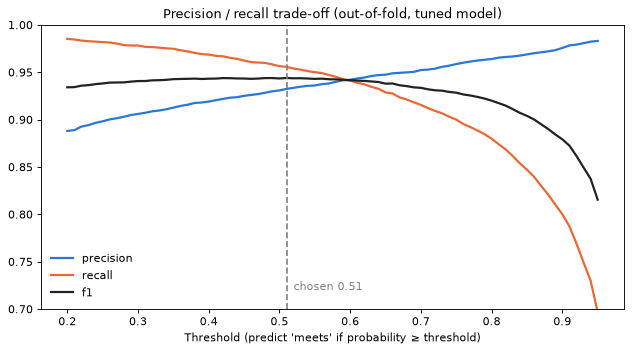

 threshold  precision  recall    f1
       0.3      0.906   0.978 0.941
       0.4      0.919   0.969 0.943
       0.5      0.931   0.956 0.943
       0.6      0.942   0.941 0.942
       0.7      0.952   0.915 0.934
       0.8      0.964   0.880 0.920
       0.9      0.976   0.800 0.879


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for col, c in [("precision", "#2a78d6"), ("recall", "#eb6834"), ("f1", "#222222")]:
    ax.plot(thr_table["threshold"], thr_table[col], label=col, color=c, lw=2)
ax.axvline(THRESHOLD, ls="--", color="grey"); ax.text(THRESHOLD + 0.01, 0.72, f"chosen {THRESHOLD:.2f}", color="grey")
ax.set_xlabel("Threshold (predict 'meets' if probability ≥ threshold)"); ax.set_ylim(0.7, 1.0)
ax.set_title("Precision / recall trade-off (out-of-fold, tuned model)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(thr_table[thr_table["threshold"].isin([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])].round(3).to_string(index=False))

**Notes:**
- **The threshold is a policy choice, not a modeling one.** The ranking stays the same; the threshold only decides where to draw the "meets / doesn't" line. Both rows in the nested table are honest: the threshold was picked inside each training split and applied to unseen schools.
- **`max_f1` (default, thresholds 0.38–0.44 inside the folds; final 0.51):** F1 **0.926 → 0.944**, recall **0.896 → 0.967**, precision 0.959 → 0.921. Good programs overlooked drop from 459 to 146; false "meets" rise from 170 to 363.
- **`precision_floor` (precision ≥ 0.96, thresholds 0.79–0.82):** precision 0.965, recall 0.879, F1 0.920. Fewer false positives than the baseline (141 vs. 170) but more good programs missed (534 vs. 459), so it's the choice only if false "meets" are much worse than missed programs.
- **The F1 curve is flat between 0.3 and 0.6 (0.941–0.943)**, so the exact `max_f1` threshold isn't fragile.
- **Recommendation:** put the **probability** into the Opportunity Score (that's what gets combined with completion, placement and demand) and use the threshold only for the yes/no flag on the dashboard. Which rule to use is the stakeholder's call; switching is one line in the setup cell.

## Calibration: can the probabilities be taken at face value?
The probability feeds the Opportunity Score (40% weight), so a predicted 0.8 should mean about 80% of such programs pass.
`class_weight="balanced"` makes the model act as if the classes were 50/50, which shifts every probability downward.

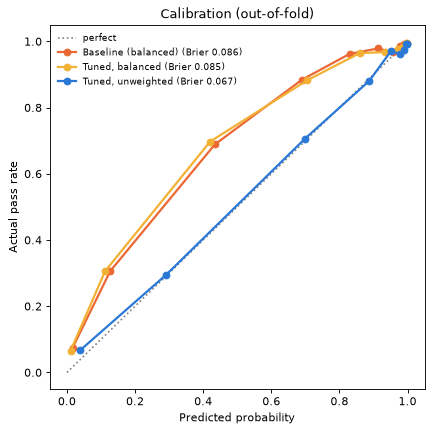

                   mean predicted  ...  Brier (lower = better)
Baseline                   0.6932  ...                  0.0855
Tuned, balanced            0.6995  ...                  0.0851
Tuned, unweighted          0.7832  ...                  0.0674

[3 rows x 4 columns]


In [11]:
oof_bal = cross_val_predict(make_tuned_pipeline(class_weight="balanced").set_params(**BEST), X, y, cv=cv,
                            groups=groups, method="predict_proba", n_jobs=-1)[:, 1]
oof_base = cross_val_predict(make_baseline_pipeline(), X, y, cv=cv, groups=groups, method="predict_proba", n_jobs=-1)[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls=":", color="grey", label="perfect")
for name, p, c in [("Baseline (balanced)", oof_base, "#eb6834"), ("Tuned, balanced", oof_bal, "#f2b134"),
                   ("Tuned, unweighted", oof_prob, "#2a78d6")]:
    fr, mp = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", lw=2, color=c, label=f"{name} (Brier {brier_score_loss(y, p):.3f})")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Actual pass rate"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Calibration (out-of-fold)"); plt.tight_layout(); plt.show()

print(pd.DataFrame({"mean predicted": [oof_base.mean(), oof_bal.mean(), oof_prob.mean()],
                    "actual pass rate": [y.mean()] * 3,
                    "ROC-AUC": [roc_auc_score(y, p) for p in (oof_base, oof_bal, oof_prob)],
                    "Brier (lower = better)": [brier_score_loss(y, p) for p in (oof_base, oof_bal, oof_prob)]},
                   index=["Baseline", "Tuned, balanced", "Tuned, unweighted"]).round(4))

**Notes:**
- **Weighting doesn't change ranking:** ROC-AUC stays at about 0.94 with or without `class_weight="balanced"`.
- **Without weighting, probabilities line up with reality:** the mean prediction (0.783) matches the actual pass rate (0.783), and the Brier score is **21% lower** (0.085 → 0.067). The balanced models sit below the diagonal: they say ~0.70 on average when the real rate is 0.78.
- **That's why the tuned model drops `class_weight="balanced"`:** imbalance is handled by the threshold, and the probability is safe to use directly in the Opportunity Score.

## Errors at the chosen threshold vs. the baseline (out-of-fold)

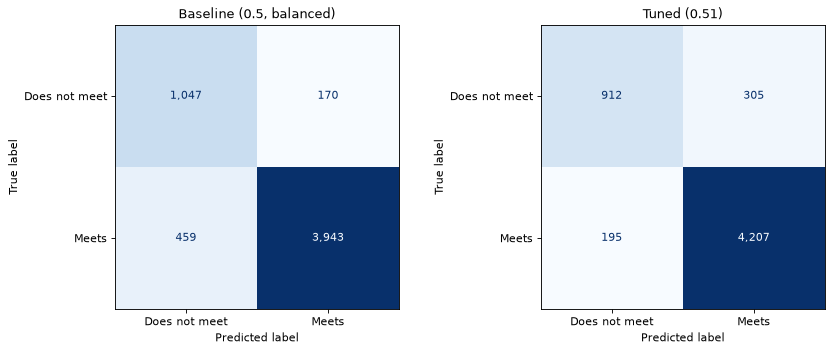

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,false positives,false negatives
Baseline,0.8881,0.9587,0.8957,0.9261,0.9420,0.9790,0.0855,170.0,459.0
Tuned,0.9110,0.9324,0.9557,0.9439,0.9442,0.9791,0.0674,305.0,195.0


In [12]:
oof_pred = (oof_prob >= THRESHOLD).astype(int)
base_pred = (oof_base >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [("Baseline (0.5, balanced)", base_pred), (f"Tuned ({THRESHOLD:.2f})", oof_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["Does not meet", "Meets"]).plot(
        ax=ax, cmap="Blues", values_format=",", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

def metrics(pred, prob):
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "roc_auc": roc_auc_score(y, prob), "pr_auc": average_precision_score(y, prob),
            "brier": brier_score_loss(y, prob),
            "false positives": int(((pred == 1) & (y == 0)).sum()), "false negatives": int(((pred == 0) & (y == 1)).sum())}
compare = pd.DataFrame({"Baseline": metrics(base_pred, oof_base), "Tuned": metrics(oof_pred, oof_prob)}).T
compare.round(4)

## Coefficients after removing overlapping features
Same reading as the baseline: positive pushes toward "meets", negative toward "does not meet".
Numeric coefficients are per standard deviation (after `log1p` for the log block).

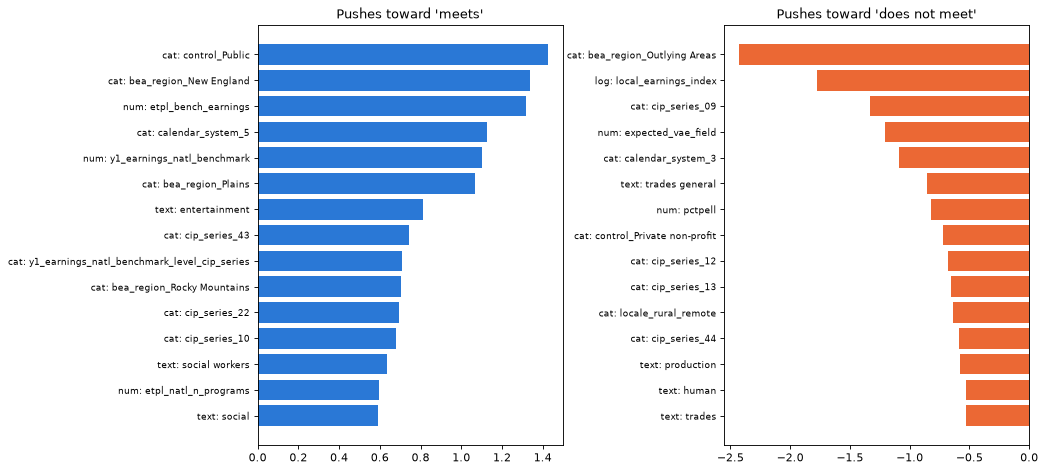

Cost, short-term and field-earnings features:
log: local_earnings_index                                  -1.774
num: expected_vae_field                                    -1.206
num: has_program_cost                                      -0.308
cat: y1_earnings_natl_benchmark_level_cip_family           -0.164
log: etpl_prog_tuition                                     -0.070
log: program_cost                                          -0.049
log: etpl_bench_tuition                                    -0.023
num: tuition_to_wage                                       -0.023
cat: y1_earnings_natl_benchmark_level_infrequent_sklearn    0.026
num: offers_cert_under_12wks                                0.069
num: costt4_a                                               0.286
num: y1_earnings_natl_cip_series                            0.333
cat: y1_earnings_natl_benchmark_level_cip_series            0.708
num: y1_earnings_natl_benchmark                             1.102
num: etpl_bench_earnings      

In [13]:
final_model = make_best().fit(X, y)
prep = final_model.named_steps["prep"]
names = [n.replace("__", ": ", 1) for n in prep.get_feature_names_out()]
coef_s = pd.Series(final_model.named_steps["clf"].coef_[0], index=names)

top_pos = coef_s.sort_values(ascending=False).head(15)
top_neg = coef_s.sort_values().head(15)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top_pos.index[::-1], top_pos.values[::-1], color="#2a78d6"); axes[0].set_title("Pushes toward 'meets'")
axes[1].barh(top_neg.index[::-1], top_neg.values[::-1], color="#eb6834"); axes[1].set_title("Pushes toward 'does not meet'")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

check = [n for n in coef_s.index if any(k in n for k in ["tuit", "costt4", "cost_to", "cert_under_12wks", "program_cost",
                                                         "earnings_natl", "etpl_bench_earnings", "expected_vae", "local_earnings"])]
print("Cost, short-term and field-earnings features:")
print(coef_s[check].sort_values().round(3).to_string())

**Notes:**
- **Field earnings drive the model:** `etpl_bench_earnings` (+1.32) and `y1_earnings_natl_benchmark` (+1.10) are the strongest positive features; fields that pay well locally and nationally clear the bar.
- **Label-construction effects remain:** `local_earnings_index` (−1.77) is strongly negative because the label divides earnings by it, as in the baseline.
- **`expected_vae_field` (−1.21) overlaps with the two features above** (it's `etpl_bench_earnings ÷ local_earnings_index − $23,475`), so the linear model splits their shared effect with opposite signs. Read these three as a group; SHAP from the tree models explains them better.
- **No more short-term-flag pair cancelling out:** `is_short_term_cert_provider` was removed in feature engineering (identical to `offers_cert_under_12wks`, now mildly +0.07).
- **Cost features are small:** program cost (−0.05), ETPL program tuition (−0.07) and tuition-to-wage (−0.02) are slightly negative (costlier programs are slightly less likely to clear the bar, other things equal). `costt4_a` is positive (+0.29), but it includes housing and living costs, so it partly tracks local cost of living. `has_program_cost` (−0.31) mostly marks schools that report prices by program (short, clock-hour, often for-profit).
- For explaining **individual** predictions in the dashboard, SHAP is still the better tool, but the global coefficients can be read as a summary.

## Fairness check by school type (out-of-fold, chosen threshold)

In [14]:
rows = []
for name, pred, prob in [("Baseline", base_pred, oof_base), ("Tuned", oof_pred, oof_prob)]:
    for grp, idx in labeled.groupby("control").groups.items():
        pos = labeled.index.get_indexer(idx)
        yt = y.loc[idx]
        rows.append({"model": name, "control": grp, "programs": len(idx), "actual pass": yt.mean(),
                     "mean prob": prob[pos].mean(), "predicted pass": pred[pos].mean(),
                     "precision": precision_score(yt, pred[pos], zero_division=0), "recall": recall_score(yt, pred[pos]),
                     "F1": f1_score(yt, pred[pos]), "ROC-AUC": roc_auc_score(yt, prob[pos])})
fair = pd.DataFrame(rows).set_index(["control", "model"]).sort_index()
fair.round(3)

programs  actual pass  ...     F1  ROC-AUC
control            model                            ...                
Private for-profit Baseline      2225        0.574  ...  0.825    0.918
                   Tuned         2225        0.574  ...  0.878    0.925
Private non-profit Baseline       226        0.743  ...  0.887    0.853
                   Tuned          226        0.743  ...  0.877    0.854
Public             Baseline      3168        0.933  ...  0.968    0.912
                   Tuned         3168        0.933  ...  0.976    0.906

[6 rows x 8 columns]

**Notes:**

| School type | Model | Actual pass | Mean probability | Predicted pass | Precision | Recall | ROC-AUC |
|---|---|---|---|---|---|---|---|
| For-profit (2,225) | Baseline | 0.574 | 0.445 | 0.470 | 0.917 | 0.750 | 0.918 |
| | Tuned | 0.574 | 0.575 | 0.591 | 0.865 | **0.891** | 0.925 |
| Non-profit (226) | Baseline | 0.743 | 0.623 | 0.704 | 0.912 | 0.863 | 0.853 |
| | Tuned | 0.743 | 0.746 | 0.770 | 0.862 | **0.893** | 0.854 |
| Public (3,168) | Baseline | 0.933 | 0.872 | 0.918 | 0.976 | 0.960 | 0.912 |
| | Tuned | 0.933 | 0.932 | 0.954 | 0.966 | **0.987** | 0.906 |

- **The baseline's main fairness gap mostly closes.** For-profit recall goes from **0.750 to 0.891** (about 1 in 4 good for-profit programs missed → about 1 in 9). Non-profit recall goes from 0.863 to 0.893.
- **Probabilities are calibrated within each school type:** the mean predicted probability matches the actual pass rate (for-profit 0.575 vs. 0.574, non-profit 0.746 vs. 0.743, public 0.932 vs. 0.933). The baseline under-predicted every group by 6–13 points.
- **Trade-off:** precision for private schools drops (for-profit 0.917 → 0.865, non-profit 0.912 → 0.862), and the yes/no flag now slightly *over*-predicts passing (for-profit 59% predicted vs. 57% actual). Under the `precision_floor` rule this reverses.
- **Within-group ROC-AUC (0.85–0.93) barely moves.** Ranking programs *within* a school type is still the hard part, and a linear model can't improve it further.

## Held-out test set
The tuned model (fit on the training rows, threshold chosen from out-of-fold predictions) and the baseline are each
scored once on the `test` programs, which come from schools never used for training, tuning or threshold choice.

In [15]:
def test_metrics(model, threshold):
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {"threshold": threshold, "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, prob),
            "pr_auc": average_precision_score(y_test, prob), "brier": brier_score_loss(y_test, prob),
            "false positives": int(((pred == 1) & (y_test == 0)).sum()),
            "false negatives": int(((pred == 0) & (y_test == 1)).sum())}

baseline_fit = make_baseline_pipeline().fit(X, y)
test_compare = pd.DataFrame({"Baseline (0.5)": test_metrics(baseline_fit, 0.5),
                             f"Tuned ({THRESHOLD:.2f})": test_metrics(final_model, THRESHOLD)}).T
print(f"Test programs: {len(y_test):,} | pass rate {y_test.mean():.1%}")
test_compare.round(4)

Test programs: 1,405 | pass rate 78.4%


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,false positives,false negatives
Baseline (0.5),0.50,0.8932,0.9741,0.8874,0.9287,0.9566,0.9866,0.0830,26.0,124.0
Tuned (0.51),0.51,0.9132,0.9414,0.9482,0.9448,0.9605,0.9884,0.0611,65.0,57.0


**Notes:**

| Held-out test (1,405 programs, 437 schools) | Threshold | Accuracy | Precision | Recall | F1 | ROC-AUC | Brier | False pos. | False neg. |
|---|---|---|---|---|---|---|---|---|---|
| Baseline | 0.50 | 0.893 | 0.974 | 0.887 | 0.929 | 0.957 | 0.083 | 26 | 124 |
| **Tuned** | 0.51 | **0.913** | 0.941 | **0.948** | **0.945** | **0.961** | **0.061** | 65 | 57 |

- **The tuning gains hold up on schools the model never saw:** F1 0.929 → 0.945, ROC-AUC 0.957 → 0.961, Brier 0.083 → 0.061 (better-calibrated probabilities).
- **Same trade-off as in cross-validation:** the tuned model misses far fewer good programs (57 vs. 124) at the cost of more false "meets" (65 vs. 26).
- Test scores are slightly higher than cross-validation for both models, so the CV estimates weren't optimistic.


## Score every program and save

In [16]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_lr_tuned"] = final_model.predict_proba(df[INPUT_COLS])[:, 1]
df["vae_flag_lr_tuned"] = (df["p_vae_lr_tuned"] >= THRESHOLD).astype(int)
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["unitid", "instnm", "state", "cipcode", "cipdesc", "control", "split",
          "vae_positive_local", "earnings_1yr_local_adj", "p_vae_lr_tuned", "vae_flag_lr_tuned", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_predictions.csv", index=False)
joblib.dump({"model": final_model, "threshold": THRESHOLD, "threshold_rule": THRESHOLD_RULE, "params": BEST},
            f"{OUTPUT_DIR}/lr_tfidf_tuned_model.joblib")
compare.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_vs_baseline.csv")
ablation.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_ablation.csv")
test_compare.to_csv(f"{OUTPUT_DIR}/lr_tfidf_tuned_test_results.csv")

print("Saved predictions:", out.shape, "| threshold:", THRESHOLD)
print("Unlabeled programs flagged 'meets':", f"{df.loc[df['split'] == 'score_only', 'vae_flag_lr_tuned'].mean():.1%}")

Saved predictions: (26678, 12) | threshold: 0.51
Unlabeled programs flagged 'meets': 88.6%


**Notes:**
- **89% of unlabeled programs are flagged "meets"** (vs. 78% of labeled ones). That's plausible, since unlabeled programs are mostly public (labeled data over-represents for-profit schools, 39% vs. 16%) and public programs pass 93% of the time. But these programs have no earnings data to check against, so treat their scores as extrapolations and prefer the probability over the flag.
- `p_vae_oof` is the honest score for training programs; `p_vae_lr_tuned` comes from the model fit on the training data (used for test and unlabeled programs).

## Summary

*Rerun on the feature-engineered data (`data/processed/model/model_features.csv`) with the shared train/test split and CV folds.*

| | Baseline | Tuned |
|---|---|---|
| ROC-AUC (5-fold CV) | 0.942 | **0.944** (nested: 0.944) |
| F1 (out-of-fold) | 0.926 | **0.944** (`max_f1`, threshold 0.51) / 0.920 (`precision_floor`) |
| Precision / recall (out-of-fold) | 0.959 / 0.896 | 0.932 / 0.956 (`max_f1`) · 0.965 / 0.879 (`precision_floor`) |
| False positives / false negatives (out-of-fold) | 170 / 459 | 305 / 195 (`max_f1`) · 141 / 534 (`precision_floor`) |
| Brier (calibration, lower = better) | 0.086 | **0.067** |
| For-profit recall | 0.750 | **0.891** |
| **Held-out test F1 / ROC-AUC** | 0.929 / 0.957 | **0.945 / 0.961** |
| Features | 109 numeric + 11 one-hot categories + text | 94 numeric (35 log-transformed) + 11 one-hot categories + text |

- **Ranking ability:** essentially unchanged (0.942 → 0.944). Feature engineering already removed most overlapping columns, so the extra clean-up here adds little. Logistic regression is at its ceiling; use the tree models to rank better.
- **F1:** 0.926 → 0.944 out-of-fold and 0.929 → 0.945 on the held-out test set, from dropping class weights and choosing the threshold.
- **Calibration:** dropping `class_weight="balanced"` makes probabilities match actual pass rates overall and within each school type, so the probability can go straight into the Opportunity Score.
- **Explainability:** 15 remaining overlapping features removed; field-earnings features read as a group.
- **Fairness:** the for-profit recall gap from the baseline (0.750) mostly closes (0.891).
- **Open decision for the team / stakeholder:** which threshold rule to use for the yes/no flag. The probability itself doesn't depend on it.

What the model does

It predicts whether a certificate program clears the Workforce Pell earnings bar: locally adjusted earnings above $23,475.
It uses the program's numbers (cost, completion, local wages, etc.) plus the text of its field name and related job titles.
We picked logistic regression as the baseline because it's simple and explains itself: each feature pushes the prediction up or down.

Choices in the baseline

Each school stays on one side of the train/test split. Programs from the same school never appear in both training and testing, so the model is always judged on schools it hasn't seen. All models share the same split, so their results can be compared.
Student race/ethnicity is left out. A funding score shouldn't rate programs by who they serve. Leaving it out cost no accuracy, and we kept it in the dataset for fairness checks.
We focus on F1 and ROC-AUC, not accuracy. 78% of programs pass, so guessing "pass" every time would already score 78% accuracy.

What tuning changed

Removed 15 more overlapping columns. Feature engineering had already removed most duplicates; the rest (for example tuition vs. cost of attendance, or missing-data flags that mark the same schools) were splitting their effect, which made the model hard to explain.
Made the probabilities honest. The baseline's probabilities were about 9 points too low on average. Now a predicted 80% really means about 80% of those programs pass. This matters because the probability feeds the Opportunity Score.
Chose the cutoff on purpose. Instead of a default 50% cutoff, we picked it from the data, and the team can choose between two rules:
Balanced (default): catches many more good programs, with more false "passes".
Strict: fewer false "passes" than the baseline, but misses more good programs.
Tested honestly. All tuning decisions were made without looking at the schools used to score the model, and the final model was checked once on a held-out test set.

Results

F1 went from 0.926 to 0.944 (0.929 to 0.945 on the held-out test set). We now miss about 195 good programs instead of 460.
ROC-AUC went from 0.942 to 0.944, a small gain. Logistic regression is near its limit here; the tree models rank programs better.
Fairness improved: the baseline missed 1 in 4 good for-profit programs, and now it misses about 1 in 9.